# Grad-CAM Analysis for Attention U-Net
## Brain Tumor Segmentation - Model Interpretability

This notebook implements Grad-CAM (Gradient-weighted Class Activation Mapping) to visualize which regions the Attention U-Net focuses on when making predictions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Model
import nibabel as nib
from pathlib import Path
import cv2
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

TensorFlow version: 2.20.0
GPU Available: []


## 1. Load Attention U-Net Model

In [8]:
# Load the Attention U-Net model
model_path = r'E:\Radiomics\attention\attention_model.keras'

try:
    model = keras.models.load_model(model_path, compile=False)
    print(f"✓ Loaded Attention U-Net successfully")
    print(f"  Input shape: {model.input_shape}")
    print(f"  Output shape: {model.output_shape}")
    print(f"  Total parameters: {model.count_params():,}")
    print(f"  Total layers: {len(model.layers)}")
except Exception as e:
    print(f"✗ Error loading model: {e}")

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

✓ Loaded Attention U-Net successfully
  Input shape: (None, 112, 112, 112, 4)
  Output shape: (None, 112, 112, 112, 4)
  Total parameters: 22,765,320
  Total layers: 100


## 2. Load Test Sample

In [9]:
TARGET_SIZE = 112

def crop_or_pad_volume(volume, target_size):
    """Crop or pad volume to target size"""
    current_shape = volume.shape[:3]
    result = volume.copy()
    
    for i in range(3):
        if current_shape[i] > target_size:
            start = (current_shape[i] - target_size) // 2
            end = start + target_size
            if i == 0:
                result = result[start:end, :, :, ...]
            elif i == 1:
                result = result[:, start:end, :, ...]
            else:
                result = result[:, :, start:end, ...]
        elif current_shape[i] < target_size:
            pad_before = (target_size - current_shape[i]) // 2
            pad_after = target_size - current_shape[i] - pad_before
            if i == 0:
                result = np.pad(result, ((pad_before, pad_after), (0, 0), (0, 0), (0, 0)), mode='constant')
            elif i == 1:
                result = np.pad(result, ((0, 0), (pad_before, pad_after), (0, 0), (0, 0)), mode='constant')
            else:
                result = np.pad(result, ((0, 0), (0, 0), (pad_before, pad_after), (0, 0)), mode='constant')
    
    return result

def load_sample(folder_path, target_size=112):
    """Load and preprocess a single 3D volume"""
    sample_id = folder_path.name
    
    flair = nib.load(folder_path / f"{sample_id}_flair.nii.gz").get_fdata()
    t1 = nib.load(folder_path / f"{sample_id}_t1.nii.gz").get_fdata()
    t1ce = nib.load(folder_path / f"{sample_id}_t1ce.nii.gz").get_fdata()
    t2 = nib.load(folder_path / f"{sample_id}_t2.nii.gz").get_fdata()
    seg = nib.load(folder_path / f"{sample_id}_seg.nii.gz").get_fdata()
    
    image = np.stack([flair, t1, t1ce, t2], axis=-1)
    
    for i in range(4):
        img_channel = image[..., i]
        if img_channel.max() > 0:
            image[..., i] = (img_channel - img_channel.mean()) / (img_channel.std() + 1e-8)
    
    image = crop_or_pad_volume(image, target_size)
    seg_expanded = np.expand_dims(seg, axis=-1)
    seg_processed = crop_or_pad_volume(seg_expanded, target_size)
    seg = seg_processed[..., 0]
    
    return image, seg, sample_id

# Load a test sample
data_dir = Path(r'E:\Radiomics\data')
sample_folder = sorted([f for f in data_dir.iterdir() if f.is_dir()])[0]

img, mask, sample_id = load_sample(sample_folder, target_size=TARGET_SIZE)
print(f"\n✓ Loaded sample: {sample_id}")
print(f"  Image shape: {img.shape}")
print(f"  Mask shape: {mask.shape}")


✓ Loaded sample: BraTS2021_00000
  Image shape: (112, 112, 112, 4)
  Mask shape: (112, 112, 112)


## 3. Find Convolutional Layers

In [10]:
# Find all convolutional layers in the model
print("\nSearching for convolutional layers...")
conv_layers = []

for layer in model.layers:
    if 'conv' in layer.name.lower():
        try:
            # Get output shape using the layer's output
            output_shape = layer.output.shape if hasattr(layer, 'output') else None
            if output_shape and len(output_shape) == 5:
                conv_layers.append(layer.name)
                print(f"  {layer.name}: {output_shape}")
        except:
            pass

if conv_layers:
    last_conv_layer = conv_layers[-1]
    print(f"\n✓ Using layer '{last_conv_layer}' for Grad-CAM")
else:
    print("\n✗ No suitable convolutional layer found!")
    # Try alternative approach - just use any conv layer
    print("\nSearching for alternative layers...")
    for layer in model.layers:
        if 'conv' in layer.name.lower():
            try:
                output_shape = layer.output.shape if hasattr(layer, 'output') else 'N/A'
                print(f"  {layer.name}: {output_shape}")
                if not conv_layers:
                    conv_layers.append(layer.name)
                    last_conv_layer = layer.name
            except:
                pass
    if conv_layers:
        print(f"\n✓ Using fallback layer '{last_conv_layer}' for Grad-CAM")


Searching for convolutional layers...
  conv3d_31: (None, 112, 112, 112, 32)
  conv3d_32: (None, 112, 112, 112, 32)
  conv3d_33: (None, 56, 56, 56, 64)
  conv3d_34: (None, 56, 56, 56, 64)
  conv3d_35: (None, 28, 28, 28, 128)
  conv3d_36: (None, 28, 28, 28, 128)
  conv3d_37: (None, 14, 14, 14, 256)
  conv3d_38: (None, 14, 14, 14, 256)
  conv3d_39: (None, 7, 7, 7, 512)
  conv3d_40: (None, 7, 7, 7, 512)
  conv3d_transpose_4: (None, 14, 14, 14, 256)
  conv3d_41: (None, 14, 14, 14, 256)
  conv3d_42: (None, 14, 14, 14, 256)
  conv3d_43: (None, 14, 14, 14, 1)
  conv3d_44: (None, 14, 14, 14, 256)
  conv3d_45: (None, 14, 14, 14, 256)
  conv3d_transpose_5: (None, 28, 28, 28, 128)
  conv3d_46: (None, 28, 28, 28, 128)
  conv3d_47: (None, 28, 28, 28, 128)
  conv3d_48: (None, 28, 28, 28, 1)
  conv3d_49: (None, 28, 28, 28, 128)
  conv3d_50: (None, 28, 28, 28, 128)
  conv3d_transpose_6: (None, 56, 56, 56, 64)
  conv3d_51: (None, 56, 56, 56, 64)
  conv3d_52: (None, 56, 56, 56, 64)
  conv3d_53: (None, 

## 3. Alternative: List All Layers (if above fails)

In [11]:
# If the above cell fails, run this to see all layers and manually select one
print("\nAll model layers:")
print("="*80)
for i, layer in enumerate(model.layers):
    layer_type = type(layer).__name__
    print(f"{i:3d}. {layer.name:40s} Type: {layer_type}")
    
# If automatic detection failed, manually set the layer name here:
# Example: last_conv_layer = 'conv3d_12'  # Replace with actual layer name from list above
if not conv_layers:
    print("\n" + "="*80)
    print("⚠️  Automatic layer detection failed!")
    print("Please manually set 'last_conv_layer' by uncommenting the line above")
    print("and choosing a Conv3D layer from the list (preferably one near the end)")
    print("="*80)


All model layers:
  0. input_layer_1                            Type: InputLayer
  1. conv3d_31                                Type: Conv3D
  2. batch_normalization_18                   Type: BatchNormalization
  3. activation_26                            Type: Activation
  4. conv3d_32                                Type: Conv3D
  5. batch_normalization_19                   Type: BatchNormalization
  6. activation_27                            Type: Activation
  7. max_pooling3d_4                          Type: MaxPooling3D
  8. spatial_dropout3d_4                      Type: SpatialDropout3D
  9. conv3d_33                                Type: Conv3D
 10. batch_normalization_20                   Type: BatchNormalization
 11. activation_28                            Type: Activation
 12. conv3d_34                                Type: Conv3D
 13. batch_normalization_21                   Type: BatchNormalization
 14. activation_29                            Type: Activation
 15. max_poo

## 4. Define Grad-CAM Function

In [17]:
def get_gradcam_heatmap(model, img_array, last_conv_layer_name, pred_index=None):
    """
    Generate Grad-CAM heatmap for 3D model
    
    Args:
        model: Keras model
        img_array: Input image (1, 112, 112, 112, 4)
        last_conv_layer_name: Name of the last conv layer
        pred_index: Class index to compute Grad-CAM for
    
    Returns:
        heatmap: 3D numpy array with Grad-CAM values
    """
    # Create gradient model
    grad_model = Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )
    
    # Compute gradients
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        
        # Ensure predictions is a tensor, not a list
        if isinstance(predictions, list):
            predictions = predictions[0]
        
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        
        # Get the predicted class channel - use gather to extract specific class
        # predictions shape: (batch, height, width, depth, classes)
        class_channel = predictions[..., pred_index]
        
        # Take the mean across spatial dimensions for the loss
        loss = tf.reduce_mean(class_channel)
    
    # Compute gradients of loss with respect to feature map
    grads = tape.gradient(loss, conv_outputs)
    
    # Global average pooling of gradients
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2, 3))
    
    # Weight feature maps by gradients
    conv_outputs = conv_outputs[0]  # Remove batch dimension
    
    # Multiply each channel by its importance weight
    heatmap = tf.zeros(conv_outputs.shape[:-1])
    for i in range(conv_outputs.shape[-1]):
        heatmap += pooled_grads[i] * conv_outputs[..., i]
    
    # Normalize heatmap
    heatmap = tf.maximum(heatmap, 0)
    if tf.reduce_max(heatmap) > 0:
        heatmap = heatmap / tf.reduce_max(heatmap)
    
    return heatmap.numpy()

print("✓ Grad-CAM function defined!")

✓ Grad-CAM function defined!


## 5. Generate Grad-CAM Heatmaps

In [18]:
# Define tumor classes
tumor_classes = {
    0: 'Background',
    1: 'Necrotic Core (NCR)',
    2: 'Edema',
    3: 'Enhancing Tumor (ET)'
}

# Prepare input
img_batch = np.expand_dims(img, axis=0)

# Get model prediction
print("\nGenerating predictions...")
pred = model.predict(img_batch, verbose=0)

# Handle model output (could be list or array)
if isinstance(pred, list):
    pred = pred[0]

pred_class = np.argmax(pred[0], axis=-1)
print(f"  Prediction shape: {pred_class.shape}")
print(f"  Prediction output shape: {pred.shape}")
print(f"  Unique classes in prediction: {np.unique(pred_class)}")

# Generate Grad-CAM for each tumor class
print(f"\nGenerating Grad-CAM heatmaps for sample: {sample_id}")
gradcam_results = {}

for class_id, class_name in tumor_classes.items():
    if class_id == 0:  # Skip background
        continue
    
    print(f"\n  Computing Grad-CAM for {class_name} (class {class_id})...")
    try:
        heatmap = get_gradcam_heatmap(
            model,
            img_batch,
            last_conv_layer,
            pred_index=class_id
        )
        gradcam_results[class_name] = heatmap
        print(f"    ✓ Heatmap shape: {heatmap.shape}")
        print(f"    ✓ Value range: [{heatmap.min():.4f}, {heatmap.max():.4f}]")
        print(f"    ✓ Non-zero values: {np.count_nonzero(heatmap)}")
    except Exception as e:
        print(f"    ✗ Error: {e}")
        import traceback
        print(f"    Details: {traceback.format_exc()[-200:]}")

print("\n✓ Grad-CAM computation completed!")
print(f"  Generated heatmaps for {len(gradcam_results)} classes")

if len(gradcam_results) == 0:
    print("\n⚠️  WARNING: No heatmaps were generated!")
    print("  This could mean:")
    print("  1. The layer name is incorrect")
    print("  2. The model output format is unexpected")
    print("  3. There's an issue with the Grad-CAM implementation")
    print(f"\n  Current layer: {last_conv_layer}")
    print(f"  Model output shape: {model.output_shape}")


Generating predictions...
  Prediction shape: (112, 112, 112)
  Prediction output shape: (1, 112, 112, 112, 4)
  Unique classes in prediction: [0 1 2 3]

Generating Grad-CAM heatmaps for sample: BraTS2021_00000

  Computing Grad-CAM for Necrotic Core (NCR) (class 1)...
    ✓ Heatmap shape: (112, 112, 112)
    ✓ Value range: [0.0000, 1.0000]
    ✓ Non-zero values: 1404928

  Computing Grad-CAM for Edema (class 2)...
    ✓ Heatmap shape: (112, 112, 112)
    ✓ Value range: [0.0000, 1.0000]
    ✓ Non-zero values: 1404928

  Computing Grad-CAM for Enhancing Tumor (ET) (class 3)...
    ✓ Heatmap shape: (112, 112, 112)
    ✓ Value range: [0.0000, 1.0000]
    ✓ Non-zero values: 1404928

✓ Grad-CAM computation completed!
  Generated heatmaps for 3 classes


## 5. Alternative Grad-CAM (if above fails)

In [19]:
# Alternative simpler Grad-CAM implementation
# Use this if the main implementation fails

def get_gradcam_simple(model, img_array, layer_name, class_idx):
    """
    Simplified Grad-CAM that's more robust to different model architectures
    """
    # Get the target layer output
    target_layer = model.get_layer(layer_name)
    
    # Create a model that outputs both the target layer and final prediction
    grad_model = tf.keras.models.Model(
        inputs=model.input,
        outputs=[target_layer.output, model.output]
    )
    
    with tf.GradientTape() as tape:
        conv_output, predictions = grad_model(img_array)
        
        # Handle different output formats
        if isinstance(predictions, (list, tuple)):
            predictions = predictions[0]
        
        # Get loss for the target class
        loss = predictions[:, :, :, :, class_idx]
        loss = tf.reduce_mean(loss)
    
    # Get gradients
    grads = tape.gradient(loss, conv_output)
    
    # Weight the feature map by gradient importance
    weights = tf.reduce_mean(grads, axis=(0, 1, 2, 3))
    
    # Create the heatmap
    cam = tf.zeros(conv_output.shape[1:4], dtype=tf.float32)
    
    for i, w in enumerate(weights):
        cam += w * conv_output[0, :, :, :, i]
    
    # ReLU and normalize
    cam = tf.nn.relu(cam)
    if tf.reduce_max(cam) > 0:
        cam = cam / tf.reduce_max(cam)
    
    return cam.numpy()

# Uncomment below to use this alternative implementation
# gradcam_results = {}
# for class_id, class_name in tumor_classes.items():
#     if class_id == 0:
#         continue
#     try:
#         heatmap = get_gradcam_simple(model, img_batch, last_conv_layer, class_id)
#         gradcam_results[class_name] = heatmap
#         print(f"✓ {class_name}: {heatmap.shape}")
#     except Exception as e:
#         print(f"✗ {class_name}: {e}")

## 6. Visualize 2D Slices with Grad-CAM Overlay

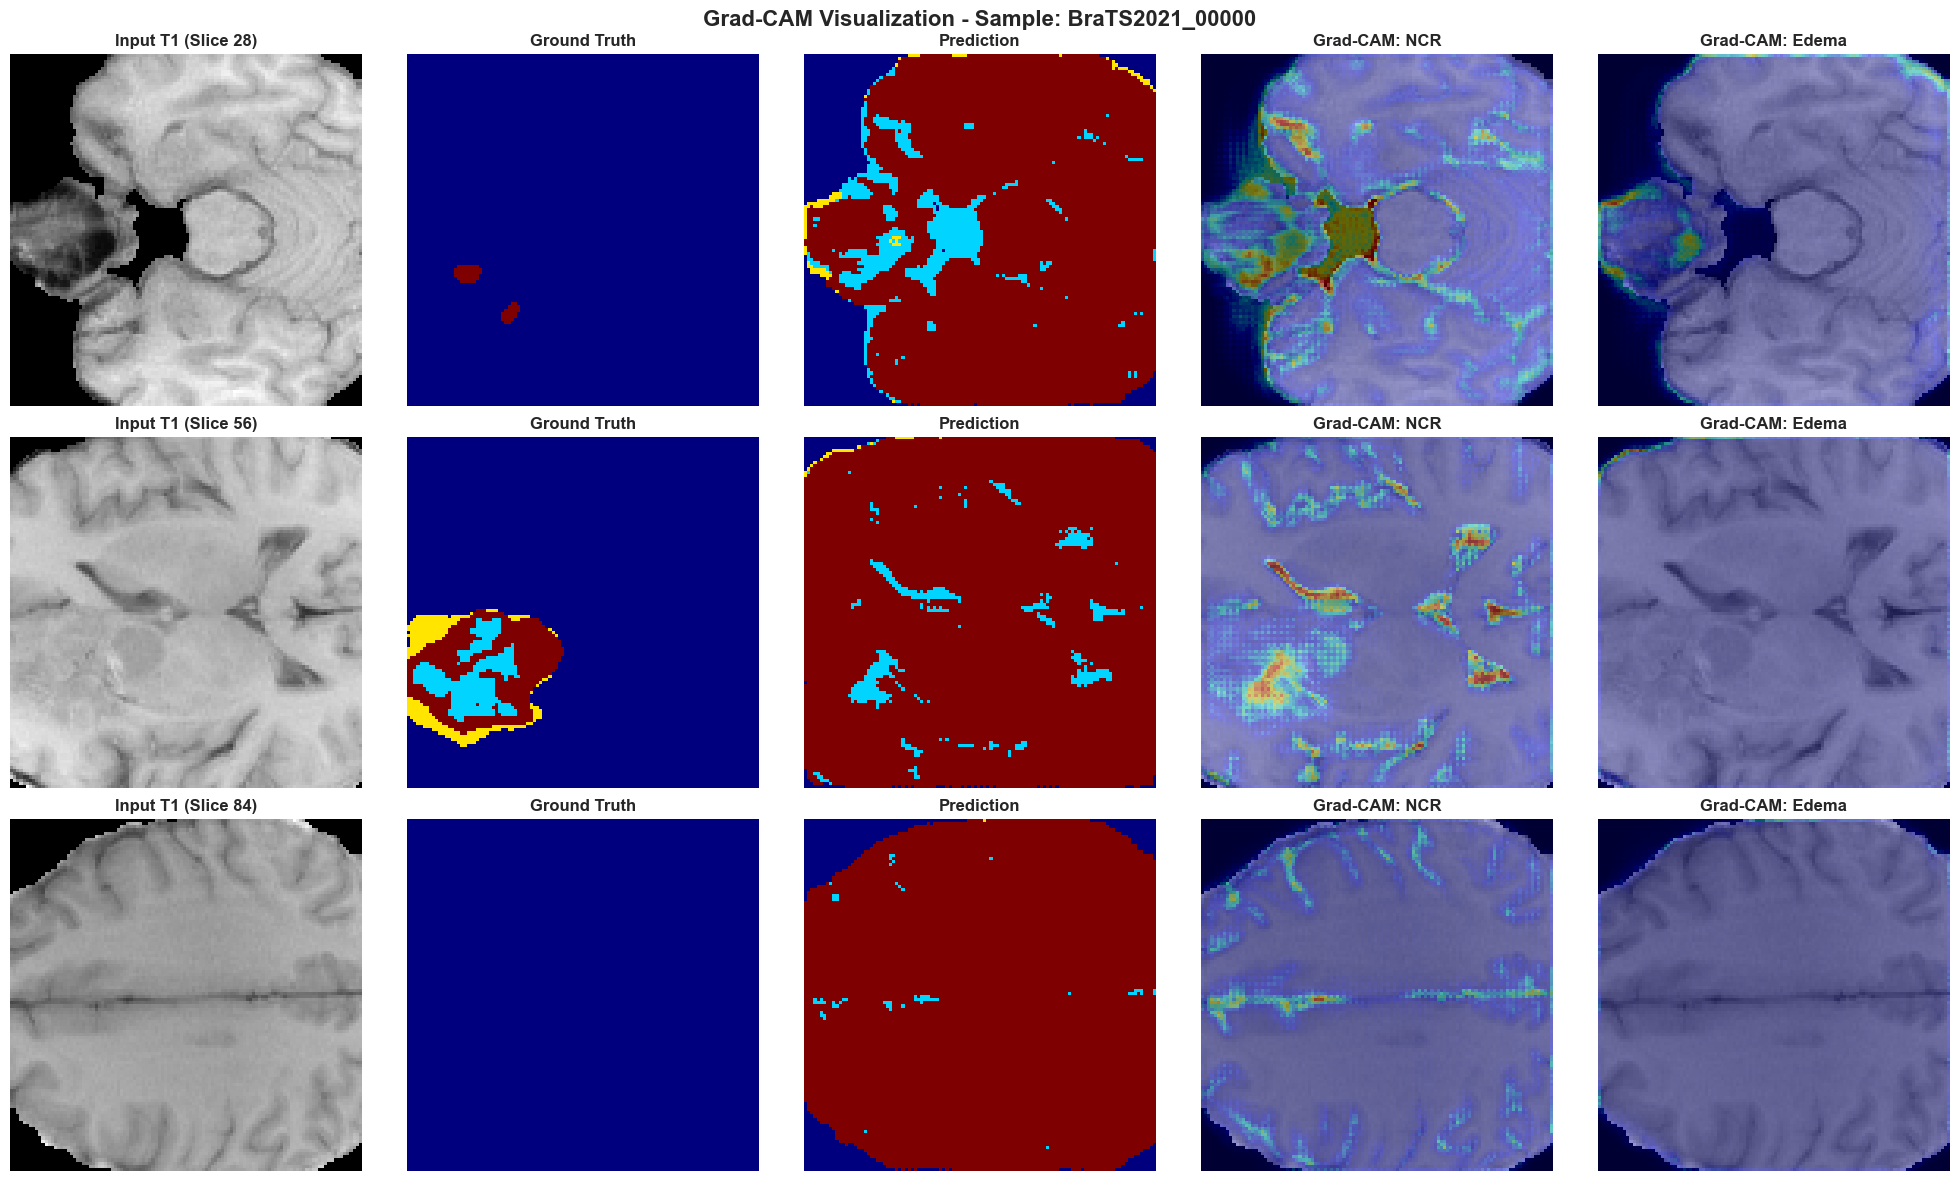


✓ 2D visualization saved as 'gradcam_2d_slices.png'


In [20]:
def overlay_heatmap_on_image(img_slice, heatmap_slice, alpha=0.4):
    """
    Overlay heatmap on grayscale image
    """
    # Normalize image
    img_min, img_max = img_slice.min(), img_slice.max()
    if img_max > img_min:
        img_normalized = ((img_slice - img_min) / (img_max - img_min) * 255).astype(np.uint8)
    else:
        img_normalized = np.zeros_like(img_slice, dtype=np.uint8)
    
    # Resize heatmap if needed
    if heatmap_slice.shape != img_normalized.shape:
        heatmap_resized = cv2.resize(heatmap_slice, (img_normalized.shape[1], img_normalized.shape[0]))
    else:
        heatmap_resized = heatmap_slice
    
    # Convert heatmap to RGB
    heatmap_uint8 = (heatmap_resized * 255).astype(np.uint8)
    heatmap_colored = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
    
    # Convert grayscale to RGB
    img_rgb = cv2.cvtColor(img_normalized, cv2.COLOR_GRAY2RGB)
    
    # Overlay
    overlayed = cv2.addWeighted(img_rgb, 1-alpha, heatmap_colored, alpha, 0)
    
    return overlayed

# Select slices to visualize
slice_indices = [TARGET_SIZE//4, TARGET_SIZE//2, 3*TARGET_SIZE//4]

fig, axes = plt.subplots(len(slice_indices), 5, figsize=(20, 4*len(slice_indices)))
if len(slice_indices) == 1:
    axes = axes.reshape(1, -1)

for row_idx, slice_idx in enumerate(slice_indices):
    # Original image (T1 modality)
    img_slice = img[:, :, slice_idx, 1]
    axes[row_idx, 0].imshow(img_slice, cmap='gray')
    axes[row_idx, 0].set_title(f'Input T1 (Slice {slice_idx})', fontweight='bold')
    axes[row_idx, 0].axis('off')
    
    # Ground truth
    mask_slice = mask[:, :, slice_idx]
    axes[row_idx, 1].imshow(mask_slice, cmap='jet', vmin=0, vmax=3)
    axes[row_idx, 1].set_title('Ground Truth', fontweight='bold')
    axes[row_idx, 1].axis('off')
    
    # Prediction
    pred_slice = pred_class[:, :, slice_idx]
    axes[row_idx, 2].imshow(pred_slice, cmap='jet', vmin=0, vmax=3)
    axes[row_idx, 2].set_title('Prediction', fontweight='bold')
    axes[row_idx, 2].axis('off')
    
    # Grad-CAM for NCR
    if 'Necrotic Core (NCR)' in gradcam_results:
        heatmap = gradcam_results['Necrotic Core (NCR)']
        # Resize if necessary
        if slice_idx < heatmap.shape[2]:
            heatmap_slice = cv2.resize(heatmap[:, :, slice_idx], (TARGET_SIZE, TARGET_SIZE))
            overlayed = overlay_heatmap_on_image(img_slice, heatmap_slice)
            axes[row_idx, 3].imshow(overlayed)
            axes[row_idx, 3].set_title('Grad-CAM: NCR', fontweight='bold')
        axes[row_idx, 3].axis('off')
    
    # Grad-CAM for Edema
    if 'Edema' in gradcam_results:
        heatmap = gradcam_results['Edema']
        if slice_idx < heatmap.shape[2]:
            heatmap_slice = cv2.resize(heatmap[:, :, slice_idx], (TARGET_SIZE, TARGET_SIZE))
            overlayed = overlay_heatmap_on_image(img_slice, heatmap_slice)
            axes[row_idx, 4].imshow(overlayed)
            axes[row_idx, 4].set_title('Grad-CAM: Edema', fontweight='bold')
        axes[row_idx, 4].axis('off')

plt.suptitle(f'Grad-CAM Visualization - Sample: {sample_id}', 
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('gradcam_2d_slices.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ 2D visualization saved as 'gradcam_2d_slices.png'")

## 7. 3D Volume Visualization

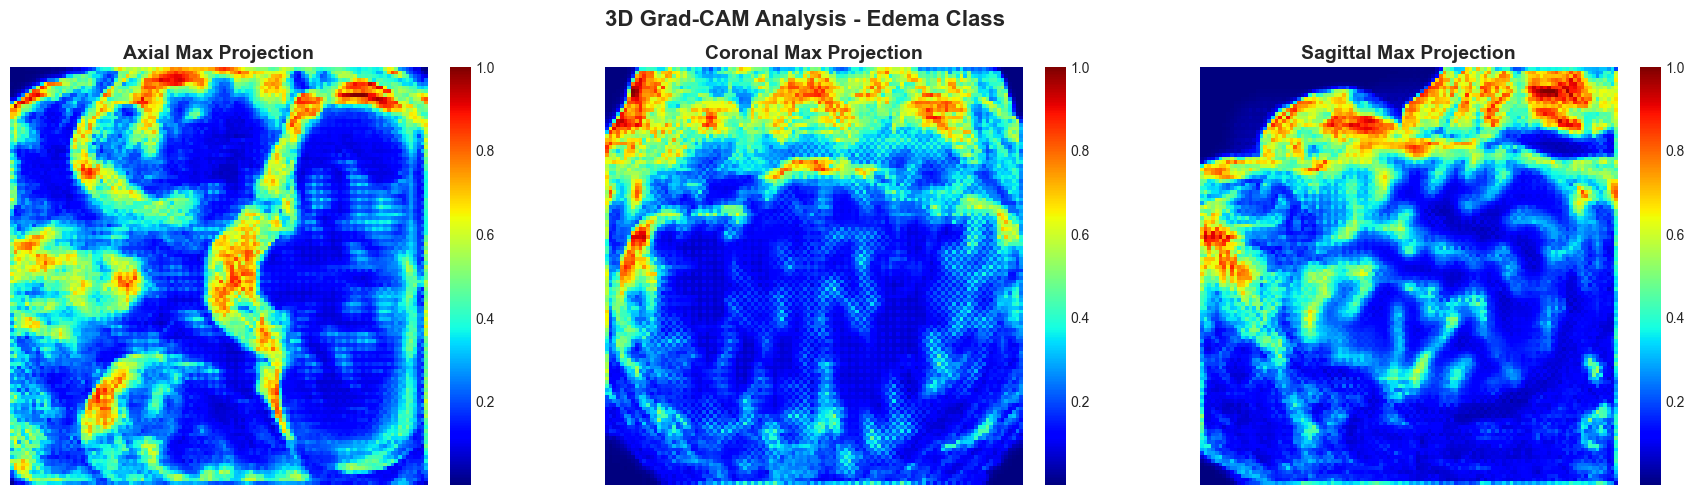


✓ 3D visualization saved as 'gradcam_3d_projections.png'


In [21]:
from mpl_toolkits.mplot3d import Axes3D

# Visualize 3D Grad-CAM for Edema class
if 'Edema' in gradcam_results:
    heatmap_3d = gradcam_results['Edema']
    
    # Resize to match input dimensions if needed
    if heatmap_3d.shape != (TARGET_SIZE, TARGET_SIZE, TARGET_SIZE):
        from scipy.ndimage import zoom
        zoom_factors = (TARGET_SIZE/heatmap_3d.shape[0], 
                       TARGET_SIZE/heatmap_3d.shape[1], 
                       TARGET_SIZE/heatmap_3d.shape[2])
        heatmap_3d = zoom(heatmap_3d, zoom_factors, order=1)
    
    # Create figure with multiple views
    fig = plt.figure(figsize=(18, 5))
    
    # 1. Axial max projection
    ax1 = fig.add_subplot(131)
    axial_proj = np.max(heatmap_3d, axis=2)
    im1 = ax1.imshow(axial_proj, cmap='jet')
    ax1.set_title('Axial Max Projection', fontsize=14, fontweight='bold')
    ax1.axis('off')
    plt.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
    
    # 2. Coronal max projection
    ax2 = fig.add_subplot(132)
    coronal_proj = np.max(heatmap_3d, axis=1)
    im2 = ax2.imshow(coronal_proj.T, cmap='jet')
    ax2.set_title('Coronal Max Projection', fontsize=14, fontweight='bold')
    ax2.axis('off')
    plt.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
    
    # 3. Sagittal max projection
    ax3 = fig.add_subplot(133)
    sagittal_proj = np.max(heatmap_3d, axis=0)
    im3 = ax3.imshow(sagittal_proj.T, cmap='jet')
    ax3.set_title('Sagittal Max Projection', fontsize=14, fontweight='bold')
    ax3.axis('off')
    plt.colorbar(im3, ax=ax3, fraction=0.046, pad=0.04)
    
    plt.suptitle('3D Grad-CAM Analysis - Edema Class', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig('gradcam_3d_projections.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("\n✓ 3D visualization saved as 'gradcam_3d_projections.png'")

## 8. Analysis Summary

In [22]:
print("\n" + "="*80)
print("GRAD-CAM ANALYSIS SUMMARY")
print("="*80)

print(f"\nSample ID: {sample_id}")
print(f"Model: Attention U-Net")
print(f"Target Layer: {last_conv_layer}")

print("\n" + "-"*80)
print("Generated Heatmaps:")
print("-"*80)
for class_name, heatmap in gradcam_results.items():
    print(f"\n{class_name}:")
    print(f"  Shape: {heatmap.shape}")
    print(f"  Min activation: {heatmap.min():.4f}")
    print(f"  Max activation: {heatmap.max():.4f}")
    print(f"  Mean activation: {heatmap.mean():.4f}")

print("\n" + "-"*80)
print("Output Files:")
print("-"*80)
print("  1. gradcam_2d_slices.png - Multi-slice 2D visualizations")
print("  2. gradcam_3d_projections.png - 3D maximum intensity projections")

print("\n" + "-"*80)
print("Interpretation Guide:")
print("-"*80)
print("  • Red/Yellow regions: High model attention (important for classification)")
print("  • Blue/Purple regions: Low model attention (less important)")
print("  • Compare heatmaps with ground truth to assess if model focuses correctly")
print("  • Strong overlap = model looking at correct regions")
print("  • Poor overlap = model may need retraining or better data")

print("\n" + "="*80)


GRAD-CAM ANALYSIS SUMMARY

Sample ID: BraTS2021_00000
Model: Attention U-Net
Target Layer: conv3d_61

--------------------------------------------------------------------------------
Generated Heatmaps:
--------------------------------------------------------------------------------

Necrotic Core (NCR):
  Shape: (112, 112, 112)
  Min activation: 0.0000
  Max activation: 1.0000
  Mean activation: 0.0988

Edema:
  Shape: (112, 112, 112)
  Min activation: 0.0000
  Max activation: 1.0000
  Mean activation: 0.0208

Enhancing Tumor (ET):
  Shape: (112, 112, 112)
  Min activation: 0.0000
  Max activation: 1.0000
  Mean activation: 0.6864

--------------------------------------------------------------------------------
Output Files:
--------------------------------------------------------------------------------
  1. gradcam_2d_slices.png - Multi-slice 2D visualizations
  2. gradcam_3d_projections.png - 3D maximum intensity projections

-------------------------------------------------------